In [1]:
from sklearn.datasets import load_wine
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
wine = load_wine()

# Convert features into a DataFrame
df = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Add the target column
df["target"] = wine.target


In [2]:
# Inspect the dataset
print(df.head())
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Class names:", wine.target_names)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [3]:
# Basic information
print(df.info())

# Statistical summary
print(df.describe())

# Number of samples in each class
print(df["target"].value_counts().sort_index())

# Average alcohol content for each class
print(df.groupby("target")["alcohol"].mean())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [4]:
# ==========================
# 3. Explore Data
# ==========================

print(df.head())
print(df.info())
print(df.describe())


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

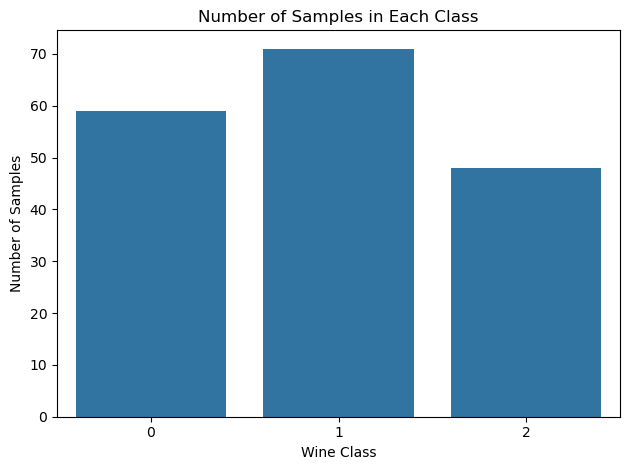

In [5]:
# ==========================
# 4. Visualize Data
# ==========================

sns.countplot(data=df, x="target")

plt.title("Number of Samples in Each Class")
plt.xlabel("Wine Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


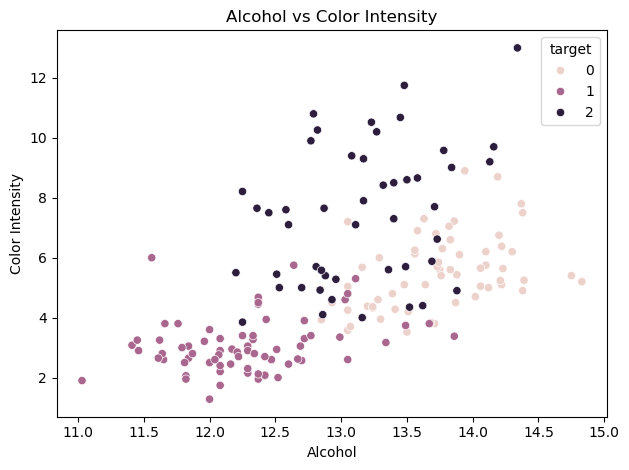

In [6]:
# ==========================
# 5. Feature Relationships
# ==========================

sns.scatterplot(
    data=df,
    x="alcohol",
    y="color_intensity",
    hue="target"
)

plt.title("Alcohol vs Color Intensity")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")
plt.tight_layout()
plt.show()

In [7]:
# ==========================
# 6. Correlation Analysis
# ==========================

features = df.drop(columns="target")

correlation = features.corr()

print(correlation.round(2))

                              alcohol  malic_acid   ash  alcalinity_of_ash  \
alcohol                          1.00        0.09  0.21              -0.31   
malic_acid                       0.09        1.00  0.16               0.29   
ash                              0.21        0.16  1.00               0.44   
alcalinity_of_ash               -0.31        0.29  0.44               1.00   
magnesium                        0.27       -0.05  0.29              -0.08   
total_phenols                    0.29       -0.34  0.13              -0.32   
flavanoids                       0.24       -0.41  0.12              -0.35   
nonflavanoid_phenols            -0.16        0.29  0.19               0.36   
proanthocyanins                  0.14       -0.22  0.01              -0.20   
color_intensity                  0.55        0.25  0.26               0.02   
hue                             -0.07       -0.56 -0.07              -0.27   
od280/od315_of_diluted_wines     0.07       -0.37  0.00         

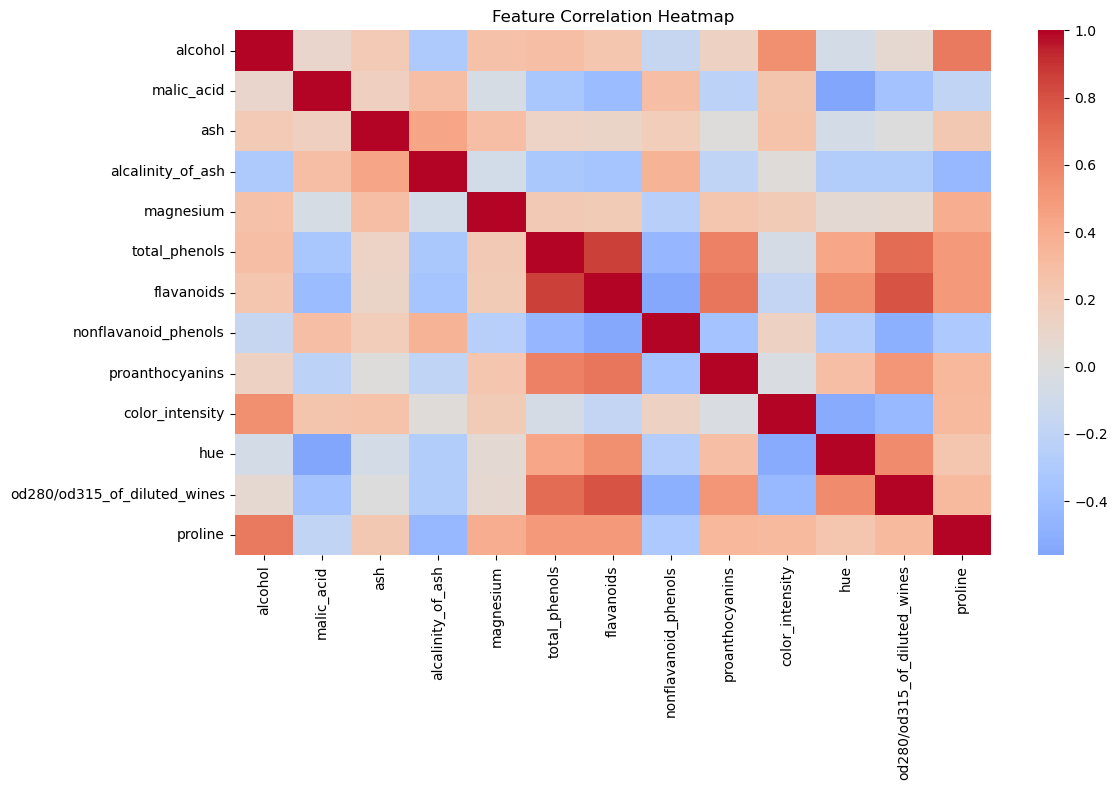

In [8]:
# ==========================
# 7. Correlation Heatmap
# ==========================

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
# ==========================
# 8. Prepare Features and Target
# ==========================

X = df.drop(columns="target")
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())

Features shape: (178, 13)
Target shape: (178,)
Number of features: 13
Number of classes: 3


In [10]:
# ==========================
# 9. Train/Test Split
# ==========================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 133
Testing samples: 45


In [11]:
# ==========================
# 10. Train the Model
# ==========================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [12]:
# ==========================
# 11. Make Predictions
# ==========================

y_pred = model.predict(X_test)

print("Actual classes:    ", y_test.iloc[:10].tolist())
print("Predicted classes: ", y_pred[:10].tolist())

Actual classes:     [0, 1, 0, 0, 1, 0, 0, 1, 1, 2]
Predicted classes:  [0, 1, 0, 0, 1, 0, 0, 1, 1, 2]


In [13]:
# ==========================
# 11. Make Predictions
# ==========================

y_pred = model.predict(X_test)

print("Actual classes:    ", y_test.iloc[:10].tolist())
print("Predicted classes: ", y_pred[:10].tolist())

Actual classes:     [0, 1, 0, 0, 1, 0, 0, 1, 1, 2]
Predicted classes:  [0, 1, 0, 0, 1, 0, 0, 1, 1, 2]


In [14]:
# ==========================
# 12. Evaluate the Model
# ==========================

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 1.0
Accuracy percentage: 100.0 %


Accuracy: 1.0


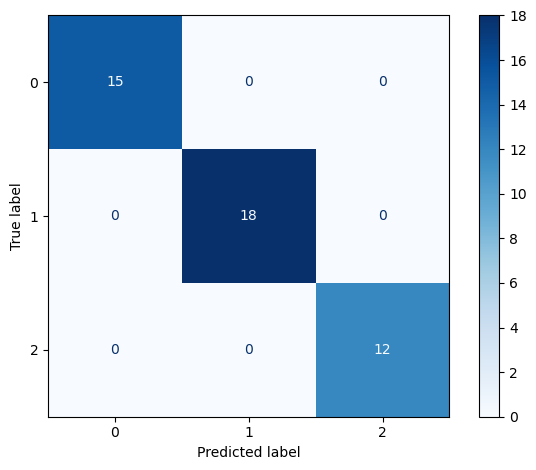

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [15]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
).plot(cmap="Blues")

plt.tight_layout()
plt.show()

# Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=wine.target_names
))

In [18]:
# ==========================
# 13. Compare Models
# ==========================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print(results_df.to_string(index=False))

              Model  Accuracy
Logistic Regression  1.000000
      Random Forest  1.000000
      Decision Tree  0.955556
                KNN  0.933333


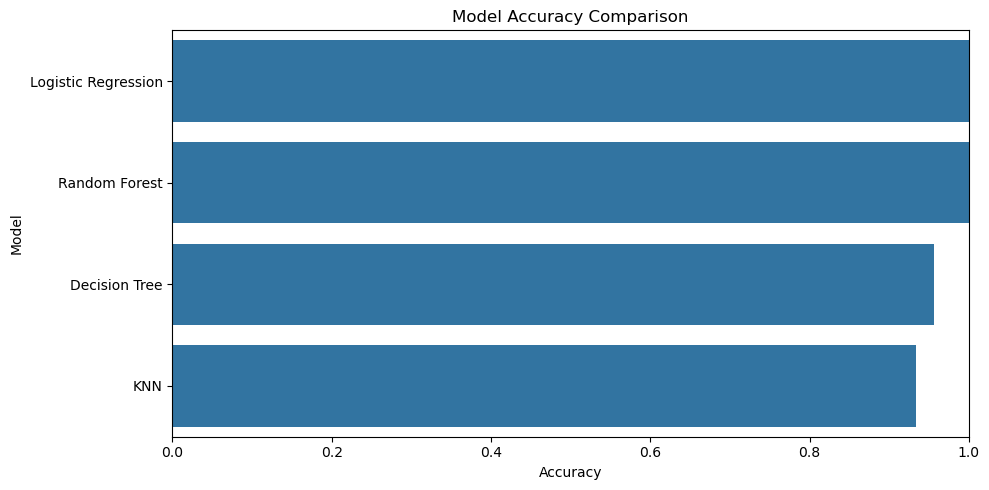

In [19]:
# ==========================
# 14. Visualize Model Comparison
# ==========================

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()